# Project 4 – Secure Boot Rollout: GP1 Coverage Check

**Source:** `data/raw/secure_boot_devices.csv`, a working sheet from an IT team rolling out a Secure Boot policy to company laptops.
The policy is deployed through a device group called **GP1**. The sheet was built to answer one question, written in its own header: *"find which is not on gp1"*.

| Column in the file | What it holds |
|---|---|
| A | **Devices in scope**: laptop host names that should have the policy |
| C | **GP1 members**: host names currently in the GP1 group |
| E | A **manual flag** typed next to each device: `OK` or `NOT ON GP1` |
| F | A lookup result: `found` or `------------` |
| H | A short hand-made list of devices believed to be missing |

A host name looks like `ASM-LTPF3D8CA3`: a **3-letter site code**, `LT` for laptop, then the **serial number**. The first two letters of the serial show the **hardware series**. `PF` is the older fleet; `SD` is the new laptops from the 2026 refresh.

**Note on privacy:** serial numbers in this public copy are replaced with consistent fake codes. Site codes and the series prefix are kept, so the analysis is unchanged.

### Business questions
1. **BQ1 Coverage:** how many in-scope devices are in GP1?
2. **BQ2 Gaps:** which devices are missing, and what do they have in common?
3. **BQ3 Tracking quality:** can the team trust its own manual flags?
4. **BQ4 Sites:** where are the missing devices?
5. **BQ5 Root cause:** are the gaps linked to the laptop refresh?

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

# One simple chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 10, "legend.frameon": False,
})
# Colours with one job each, used the same way in every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categories, in this order
GREEN, RED, GREY = "#0ca30c", "#d03b3b", "#b5b4ae"       # good / problem / not applicable
os.makedirs("../images", exist_ok=True)                   # charts are saved here for the README

## 1. Understand the file

In [2]:
# The sheet has no proper header row, so read it raw (header=None) and look at the top
raw = pd.read_csv("../data/raw/secure_boot_devices.csv", header=None, dtype=str)
print(raw.shape)
raw.head(6)

(75, 8)


,0,1,2,3,4,5,6,7
0,?,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,find which is not on gp1,NaN,gp1,NaN,NOT ON GP1,NaN,NaN,NaN
2,ASM-LTPF3D8CA3,NaN,ASM-LTPFD0D045,NaN,OK,found,NaN,NaN
3,ASM-LTPFFEC530,NaN,ASM-LTPF3D8CA3,NaN,OK,found,NaN,NaN
4,ASM-LTPF12E075,NaN,BMT-LTPF6D8D3F,NaN,OK,found,NaN,NaN
5,ASM-LTPF5ACD1F,NaN,BMT-LTPFBE298F,NaN,OK,found,NaN,NaN


In [3]:
# Rows 0-1 are notes and labels; the device lists start on row 2.
# Pull each column out as its own list and drop the empty cells.
body = raw.iloc[2:]
devices = body[0].dropna()          # column A: devices that should be on GP1
gp1 = body[2].dropna()              # column C: devices in the GP1 group
side_list = body[7].dropna()        # column H: the hand-made "missing" list

print("Devices in scope:", len(devices))
print("GP1 members:     ", len(gp1))
print("Side list:       ", len(side_list), list(side_list))

Devices in scope: 73
GP1 members:      69
Side list:        6 ['RCM-LTSDA1E289', 'LCH-LTSD6AB15F', 'ASM-LTSDBAB1AE', 'ASM-LTSD974219', 'RCM-LTSDA1E289', 'LCH-LTSD6AB15F']


## 2. Validate the data

In [4]:
# Check 1: duplicates inside each list
print("Duplicate devices in scope:", devices.duplicated().sum())
print("Duplicate GP1 members:     ", gp1.duplicated().sum())
print("Duplicates in the side list:", side_list.duplicated().sum())

Duplicate devices in scope: 0
Duplicate GP1 members:      0
Duplicates in the side list: 2


In [5]:
# Check 2: stray spaces and casing (these would break an exact match)
for name, s in [("devices", devices), ("gp1", gp1)]:
    print(name, "| with spaces:", (s != s.str.strip()).sum(), "| not upper-case:", (s != s.str.upper()).sum())

devices | with spaces: 0 | not upper-case: 0
gp1 | with spaces: 0 | not upper-case: 0


In [6]:
# Check 3: does every host name follow the SITE-LT<serial> pattern?
pattern = r"^[A-Z]{3}-LT[A-Z0-9]+$"
odd = pd.concat([devices, gp1])
odd[~odd.str.match(pattern)].unique()

<StringArray>
['SAU-LT-PF59121C']
Length: 1, dtype: str

In [7]:
# Check 4: the manual flag (column E) and the lookup (column F) for each device in scope
flags = body[[0, 4, 5]].dropna(subset=[0])
flags.columns = ["device", "manual_flag", "lookup"]
print(flags["manual_flag"].value_counts(dropna=False))
print(flags["lookup"].value_counts(dropna=False))

manual_flag
OK            67
NOT ON GP1     5
NaN            1
Name: count, dtype: int64
lookup
found           69
------------     4
Name: count, dtype: int64


### Validation summary
* **The file is a working sheet, not a table:** there are two note rows on top, the lists sit side by side, and column H holds a hand-made list. Each list is read separately.
* **Devices in scope: 73, GP1 members: 69.** No duplicates within either list, and no stray spaces or lower-case names, so an exact host-name match is safe.
* **One host name breaks the naming pattern:** `SAU-LT-PF59121C` has an extra dash. It still matches between the two lists.
* **The side list in column H has 6 entries for 4 devices** (2 are repeated).
* **The manual flag (column E) is blank for 1 device**, and it says `NOT ON GP1` 5 times while the lookup (column F) finds only 4 missing.

## 3. Reconcile the two lists

In [8]:
# The core check: is each device in scope also in GP1? (exact host-name match after trimming)
flags["device"] = flags["device"].str.strip()
gp1_set = set(gp1.str.strip())
flags["on_gp1"] = flags["device"].isin(gp1_set)

# Pull out the site code and hardware series from the host name
flags["site"] = flags["device"].str[:3]
flags["series"] = flags["device"].str.extract(r"LT-?([A-Z]{2})")[0]

missing = flags[~flags["on_gp1"]]
print("Missing from GP1:", len(missing))
missing[["device", "site", "series", "manual_flag", "lookup"]]

Missing from GP1: 4


,device,site,series,manual_flag,lookup
15,ASM-LTSDBAB1AE,ASM,SD,NOT ON GP1,------------
16,ASM-LTSD974219,ASM,SD,NOT ON GP1,------------
37,LCH-LTSD6AB15F,LCH,SD,NOT ON GP1,------------
47,RCM-LTSDA1E289,RCM,SD,NOT ON GP1,------------


In [9]:
# The other direction: is anything in GP1 that is NOT in scope?
extra = gp1_set - set(flags["device"])
print("GP1 members not in the scope list:", len(extra))

GP1 members not in the scope list: 0


## 4. Analysis

### BQ1 – Coverage

On GP1: 69 of 73 devices (94.5%)


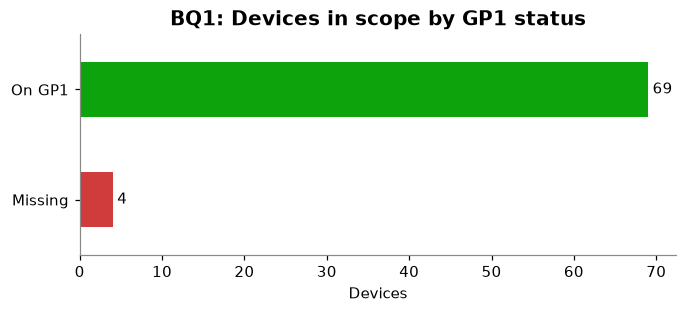

In [10]:
coverage = flags["on_gp1"].mean()
print(f"On GP1: {flags['on_gp1'].sum()} of {len(flags)} devices ({coverage:.1%})")

counts = flags["on_gp1"].map({True: "On GP1", False: "Missing"}).value_counts()[["On GP1", "Missing"]]
ax = counts.plot(kind="barh", color=[GREEN, RED], figsize=(7, 2.6), title="BQ1: Devices in scope by GP1 status")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("Devices"); ax.set_ylabel("")
plt.savefig("../images/01_bq1_coverage.png", bbox_inches="tight"); plt.show()

**Finding:** **69 of 73 in-scope devices (94.5%) are in GP1.** Every GP1 member is in scope, so the group holds nothing extra; the only gap is 4 devices that never joined.

**Recommendation:** Add the 4 missing devices to GP1 now, then re-run this check before declaring the rollout complete.

### BQ2 – What the missing devices have in common

on_gp1  On GP1  Missing
series                 
PF          68        0
PW           1        0
SD           0        4


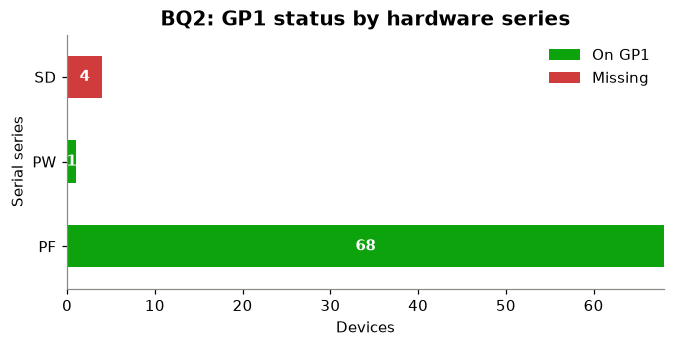

In [11]:
# Coverage by hardware series: PF = older fleet, SD = new refresh laptops
series = pd.crosstab(flags["series"], flags["on_gp1"].map({True: "On GP1", False: "Missing"}))
series = series[["On GP1", "Missing"]]
print(series)

ax = series.plot(kind="barh", stacked=True, color=[GREEN, RED], figsize=(7, 3), title="BQ2: GP1 status by hardware series")
for container in ax.containers:
    ax.bar_label(container, labels=[int(v) if v > 0 else "" for v in container.datavalues], label_type="center", color="white", fontweight="bold")
ax.set_xlabel("Devices"); ax.set_ylabel("Serial series"); ax.legend(title=None)
plt.savefig("../images/02_bq2_series.png", bbox_inches="tight"); plt.show()

**Finding:** **All 4 missing devices are SD-series laptops**, and **none of the 4 SD-series devices in scope is in GP1**. All 68 PF-series and the 1 PW-series device are covered. The gap is not random: it is exactly the new hardware.

**Recommendation:** Treat this as a process gap, not 4 one-off misses. Find the step where new SD laptops should be added to GP1, and add it to the build checklist.

### BQ3 – Can the team trust its manual flags?

In [12]:
# Compare the typed flag with the true answer from the reconciliation
flags["flag_says_missing"] = flags["manual_flag"].eq("NOT ON GP1")
check = pd.crosstab(flags["manual_flag"].fillna("(blank)"), flags["on_gp1"].map({True: "Really on GP1", False: "Really missing"}))
print(check)

wrong = flags[flags["flag_says_missing"] == flags["on_gp1"]]
print("Devices whose manual flag is wrong:"); print(wrong[["device", "manual_flag", "lookup", "on_gp1"]])
print("Devices with no manual flag:", flags["manual_flag"].isna().sum())

# The side list in column H against the true missing list
print("Side list (unique):", sorted(set(side_list.str.strip())))
print("Matches the true missing list:", set(side_list.str.strip()) == set(missing["device"]))

on_gp1       Really missing  Really on GP1
manual_flag                               
(blank)                   0              1
NOT ON GP1                4              1
OK                        0             67
Devices whose manual flag is wrong:
            device manual_flag lookup  on_gp1
51  TRV-LTPF3545AC  NOT ON GP1  found    True
Devices with no manual flag: 1
Side list (unique): ['ASM-LTSD974219', 'ASM-LTSDBAB1AE', 'LCH-LTSD6AB15F', 'RCM-LTSDA1E289']
Matches the true missing list: True


                        Correct  Wrong or blank
Lookup (column F)            73               0
Manual flag (column E)       71               2


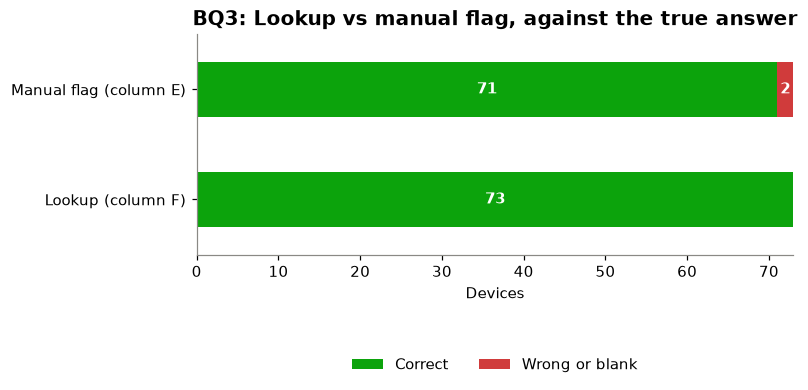

In [13]:
# How each source of truth compares with the reconciliation
summary = pd.DataFrame({
    "Correct": [int((flags["lookup"].eq("found") == flags["on_gp1"]).sum()), int((flags["flag_says_missing"] != flags["on_gp1"]).sum() - flags["manual_flag"].isna().sum())],
    "Wrong or blank": [int((flags["lookup"].eq("found") != flags["on_gp1"]).sum()), int((flags["flag_says_missing"] == flags["on_gp1"]).sum() + flags["manual_flag"].isna().sum())],
}, index=["Lookup (column F)", "Manual flag (column E)"])
print(summary)
ax = summary.plot(kind="barh", stacked=True, color=[GREEN, RED], figsize=(7, 2.6), title="BQ3: Lookup vs manual flag, against the true answer")
for container in ax.containers:
    ax.bar_label(container, labels=[int(v) if v > 0 else "" for v in container.datavalues], label_type="center", color="white", fontweight="bold")
ax.set_xlabel("Devices"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.6), ncol=2)
plt.savefig("../images/03_bq3_flag_accuracy.png", bbox_inches="tight"); plt.show()

**Finding:** The lookup in column F is right for all 73 devices. **The manual flag in column E is wrong or blank for 2**: `TRV-LTPF3545AC` is marked `NOT ON GP1` but is in the group, and one device has no flag. The side list in column H names the right 4 devices but repeats 2 of them.

**Recommendation:** Drop the hand-typed flag and keep only the formula-driven lookup (or this notebook) as the source of truth, so the status can't drift from the data.

### BQ4 – Where the devices are

on_gp1  On GP1  Missing
site                   
ASM         14        2
LCH          6        1
RCM          2        1
BMT         10        0
CLG          6        0
HFX          5        0
KST          4        0
MCT          4        0
VCR          4        0
QBC          3        0


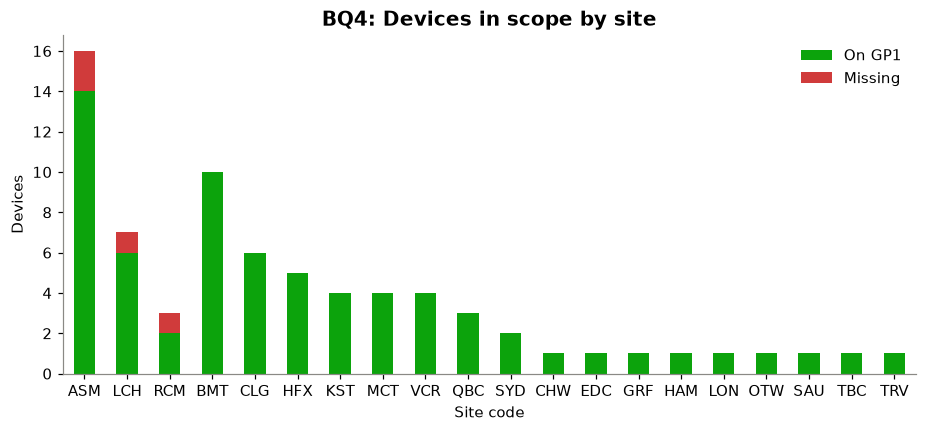

In [14]:
by_site = pd.crosstab(flags["site"], flags["on_gp1"].map({True: "On GP1", False: "Missing"}))[["On GP1", "Missing"]]
by_site = by_site.sort_values(["Missing", "On GP1"], ascending=False)
print(by_site.head(10))

ax = by_site.plot(kind="bar", stacked=True, color=[GREEN, RED], figsize=(10, 4), title="BQ4: Devices in scope by site")
ax.set_xlabel("Site code"); ax.set_ylabel("Devices"); plt.xticks(rotation=0); ax.legend(title=None)
plt.savefig("../images/04_bq4_sites.png", bbox_inches="tight"); plt.show()

**Finding:** The missing devices are at **L'Assomption (ASM, 2 of 16)**, **Lachine (LCH, 1 of 7)** and **Richmond (RCM, 1 of 3)**. Every other site is fully covered. ASM is the largest site in scope, so it carries half of the gap.

**Recommendation:** Ask the ASM, LCH and RCM site contacts to confirm the 4 laptops are in use, then add them to GP1 remotely.

### BQ5 – Is the gap linked to the laptop refresh?

In [15]:
# The refresh project's list of new laptops (host names given to new SD-series machines)
refresh = pd.read_csv("../data/raw/laptop_refresh_new_hosts.csv", dtype=str)
refresh["new_host"] = refresh["new_host"].str.strip()
print("New laptops in the refresh:", len(refresh))

# Which missing devices are new refresh laptops?
missing_refresh = missing.merge(refresh, left_on="device", right_on="new_host", how="left")
missing_refresh[["device", "site", "series", "location", "shipping_date"]]

New laptops in the refresh: 505


,device,site,series,location,shipping_date
0,ASM-LTSDBAB1AE,ASM,SD,"L'Assomption, QC",14-Aug
1,ASM-LTSD974219,ASM,SD,NaN,NaN
2,LCH-LTSD6AB15F,LCH,SD,NaN,NaN
3,RCM-LTSDA1E289,RCM,SD,"Richmond Prod, BC",14-Aug


In [16]:
# How many SD-series devices are in scope at all, and how many of them reached GP1?
sd = flags[flags["series"] == "SD"]
print("SD-series devices in scope:", len(sd), "| on GP1:", sd["on_gp1"].sum())
print("Missing devices found in the refresh list:", missing_refresh["new_host"].notna().sum(), "of", len(missing))

SD-series devices in scope: 4 | on GP1: 0
Missing devices found in the refresh list: 2 of 4


**Finding:** **2 of the 4 missing devices appear in the 2026 laptop refresh list**: `ASM-LTSDBAB1AE` (L'Assomption) and `RCM-LTSDA1E289` (Richmond), both shipped on 14 Aug. The other 2 are SD-series laptops that the refresh list doesn't include. New laptops are reaching users without being added to the Secure Boot group.

**Recommendation:** Add "join GP1" to the refresh imaging checklist, next to the existing Teams, Asset Panda and group-membership steps. Then cross-check every SD-series host name against GP1 once a week until the refresh ends.

## 5. Summary
| # | Question | Answer |
|---|---|---|
| BQ1 | Coverage | **69 of 73 (94.5%)** devices in GP1 |
| BQ2 | Gaps | All **4 missing are SD-series**: 0 of 4 new laptops covered |
| BQ3 | Tracking quality | Lookup right for 73 of 73; manual flag wrong or blank for **2** |
| BQ4 | Sites | ASM (2), LCH (1), RCM (1) |
| BQ5 | Root cause | **2 of 4** are laptops from the 2026 refresh |

**Main message:** the Secure Boot rollout covers the old fleet completely but misses every new laptop. Fixing the imaging checklist closes the gap for good.